In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('scored.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

NEIGHBOR_RANGE = list(range(1, 21))
print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)

200 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,...,cat_wrong_task,cat_too_generic,cat_truncated_incomplete,cat_correct_domain,cat_correct_task,cat_methodology_partially_correct,cat_scientific_language,cat_coherent_structure,num_of_neighbors,is_error
0,769,2942669846,Reinforcement learning usually makes use of nu...,We present an application of deep reinforcemen...,0.3567,0.0513,0.1592,0.8401,0.8534,0.8467,...,0,0,0,1,1,1,1,1,4,False
1,2012,2913127348,Gatherings of thousands to millions of people ...,Accurate crowd counting in highly congested sc...,0.2988,0.0491,0.1341,0.8426,0.8402,0.8414,...,0,0,0,1,1,0,1,1,8,False
2,3364,2942522480,"Recently, a method called the Mutual Informati...",We present a fairness-aware representation lea...,0.2685,0.0473,0.1544,0.8186,0.8233,0.8210,...,0,0,0,0,0,1,1,1,4,False


In [4]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour count (1-20)."""
    values = [series.get(n, np.nan) for n in NEIGHBOR_RANGE]

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(NEIGHBOR_RANGE, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(NEIGHBOR_RANGE)
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

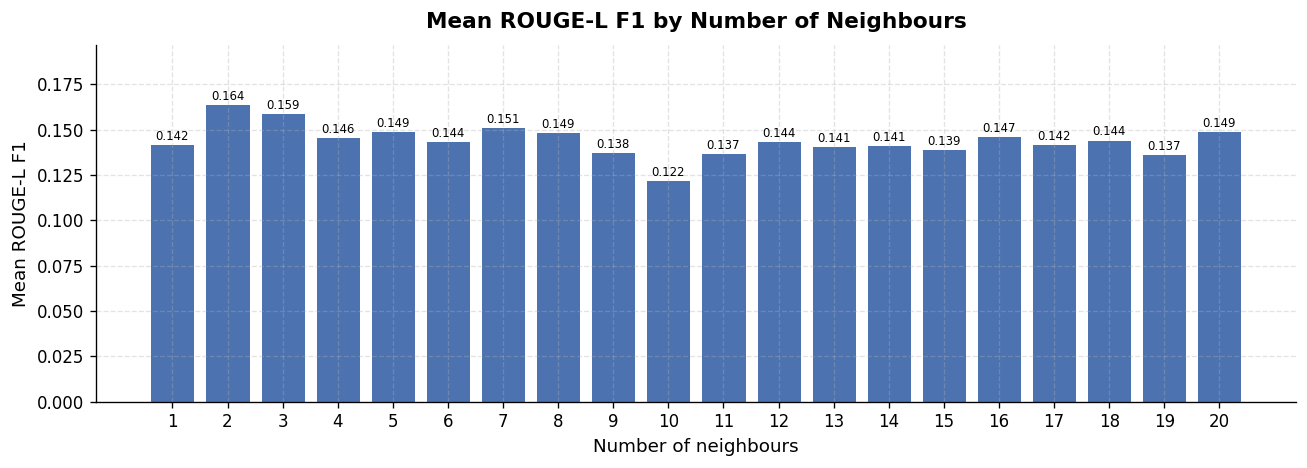

In [5]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = df.groupby('num_of_neighbors')['rougeL_f'].mean()
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

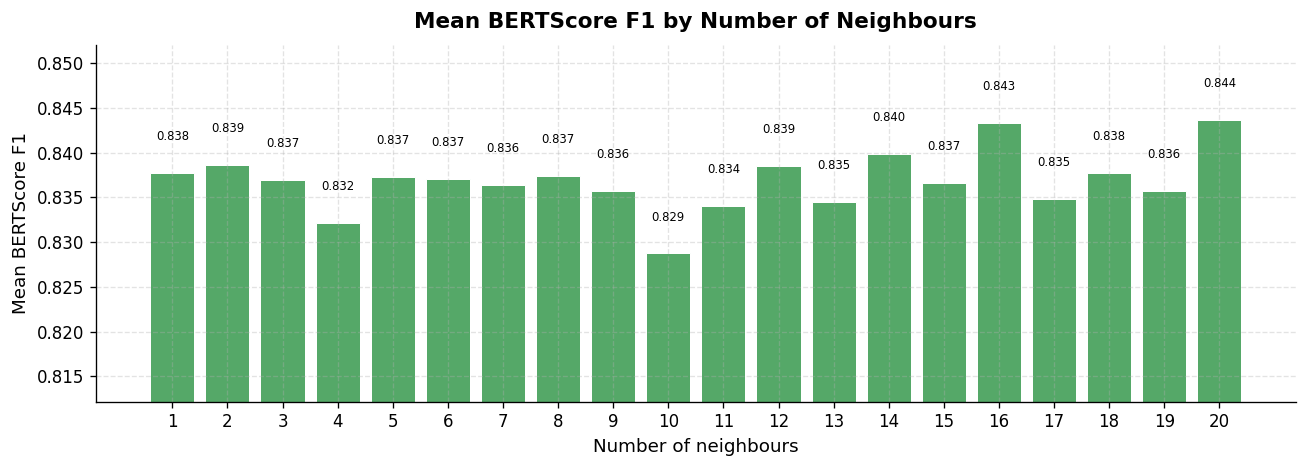

In [6]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = df.groupby('num_of_neighbors')['bertscore_f1'].mean()
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

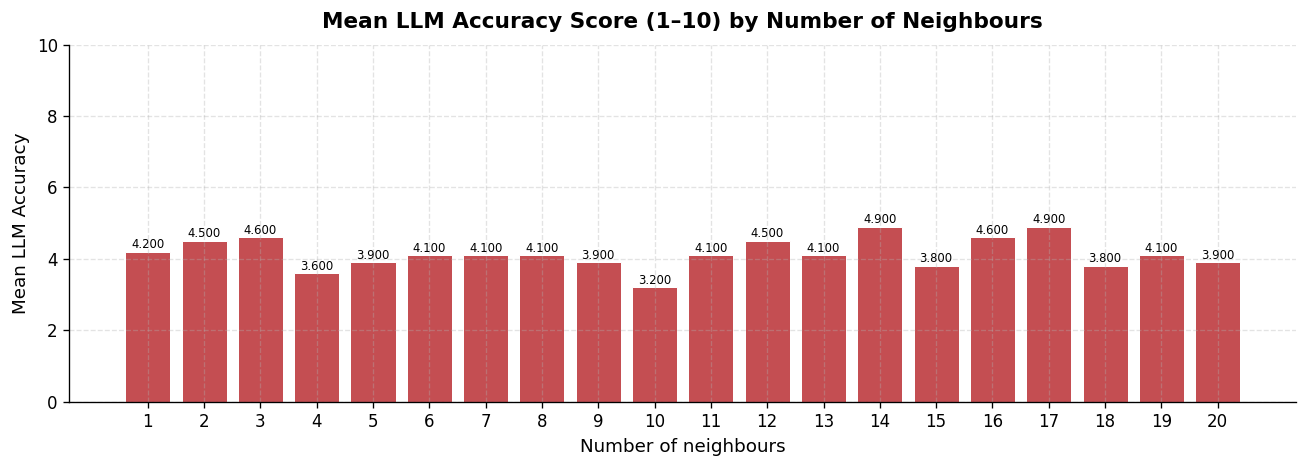

In [7]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = df.groupby('num_of_neighbors')['llm_accuracy'].mean()
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

In [ ]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

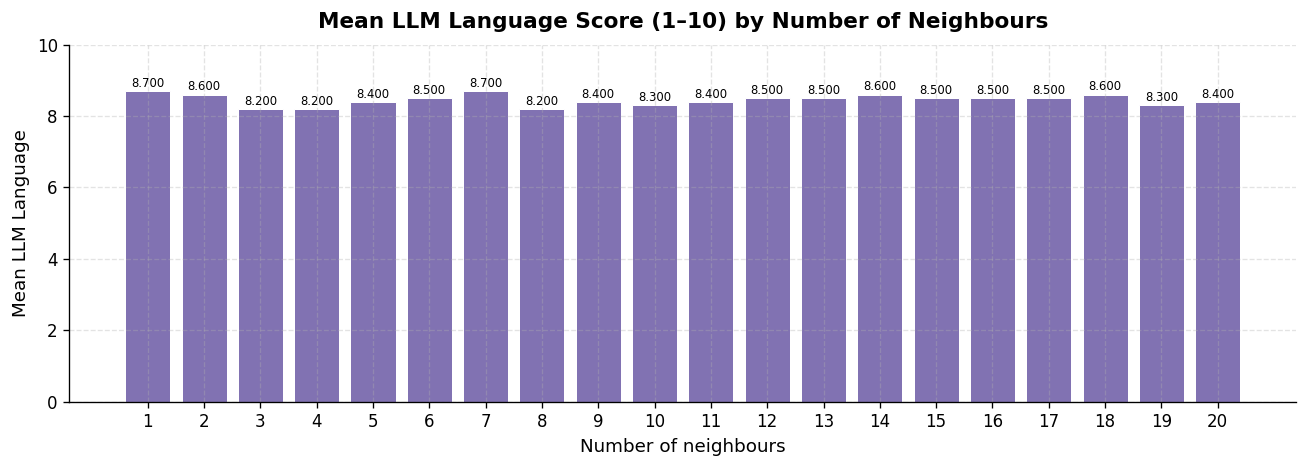

In [8]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = df.groupby('num_of_neighbors')['llm_language'].mean()
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

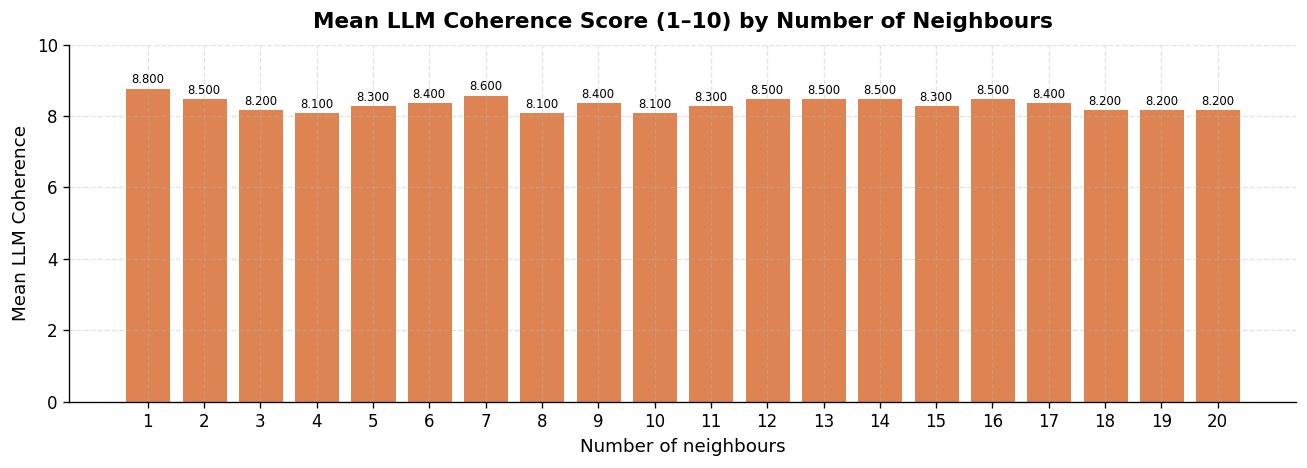

In [9]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = df.groupby('num_of_neighbors')['llm_coherence'].mean()
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

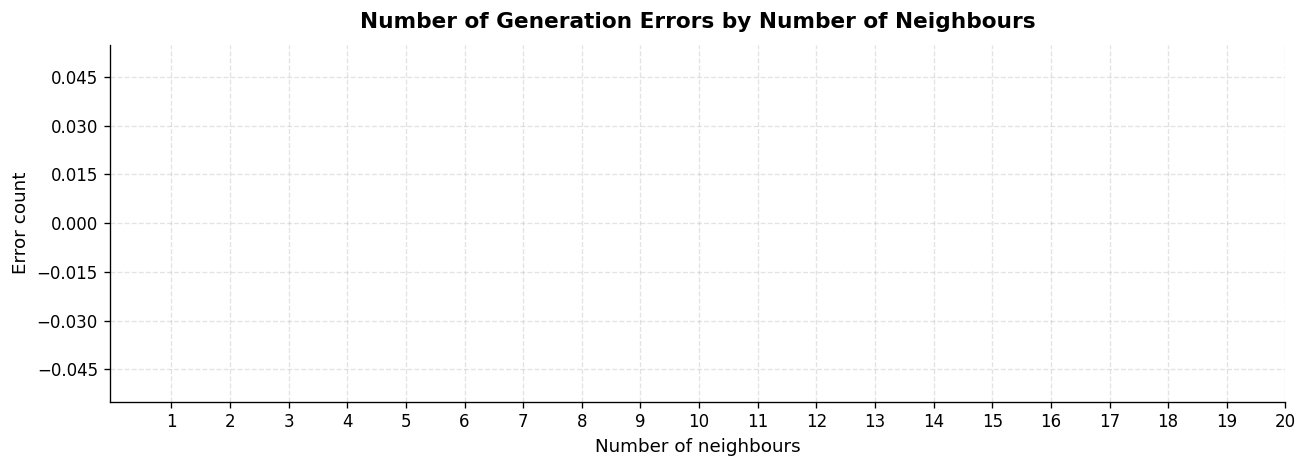

In [10]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('num_of_neighbors').size()
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [11]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_18260/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,3364,"Recently, a method called the Mutual Information Neural Estimator (MINE) that uses neural networks has been proposed to estimate mutual information and more generally the Kullback-Leibler (KL) divergence between two distributions. The method uses the Donsker-Varadhan representation to arrive at the estimate of the KL divergence and is better than the existing estimators in terms of scalability and flexibility. The output of MINE algorithm is not guaranteed to be a consistent estimator. We propose a new estimator that instead of searching among functions characterized by neural networks searches the functions in a Reproducing Kernel Hilbert Space. We prove that the proposed estimator is consistent. We carry out simulations and show that when the datasets are small the proposed estimator is more reliable than the MINE estimator and when the datasets are large the performance of the two methods are close.","We present a fairness-aware representation learning framework that combines information-maximizing generative modeling with principled bias quantification and mitigation. Building on InfoGAN, our method learns disentangled latent factors in an unsupervised manner while explicitly encouraging the representation to preserve task-relevant information through a mutual-information objective estimated with MINE. To assess and control unwanted bias, we incorporate inequality-based unfairness measures that capture both individual- and group-level disparities and expose tradeoffs between between-group and within-group unfairness. The resulting model can be trained end-to-end and integrated into a modular fairness pipeline, enabling systematic evaluation and mitigation of bias in downstream prediction tasks. Experiments on benchmark datasets show that the proposed approach learns interpretable latent factors, improves mutual-information estimation, and reduces unfairness while maintaining competitive predictive performance. These results suggest that disentangled generative representations, coupled with rigorous fairness metrics, provide a practical foundation for transparent and equitable machine learning systems.",1
1,169024,"We study the revenue maximization problem with an imprecisely estimated distribution of a single buyer or several independent and identically distributed buyers given that this estimation is not far away from the true distribution. We use the earth mover's distance to capture the estimation error between those two distributions in terms of both values and their probabilities, i.e., the error in value space given a quantile, and the error in quantile space given a value. We give explicit characterization of the optimal mechanisms for the single buyer setting. For the multi-buyer case, we provide an algorithm that finds an approximately optimal mechanism (FPTAS) among the family of second price auctions with a fixed reserve.","We study the design of approximately optimal Bayesian auctions when the seller has only limited information about bidders’ value distributions, combining sample-based learning, oracle access, and side information in multi-item settings. For independent bidders with additive, unit-demand, XOS, and related valuations, we develop efficient mechanisms that achieve near-optimal revenue from polynomially many samples or from efficient quantile/value queries, without requiring regularity or monotone hazard rate assumptions. Our approach extends empirical and max-min learning frameworks to settings with side information and approximate distributional inputs, yielding robust guarantees that apply even when the true distributions are only indirectly observed. We further leverage a reduction from revenue maximization to welfare maximization via virtual VCG allocation rules, enabling computationally efficient implementation using only black-box access to allocation oracles. The resulting mechanisms unify and strengthen prior sample-comple

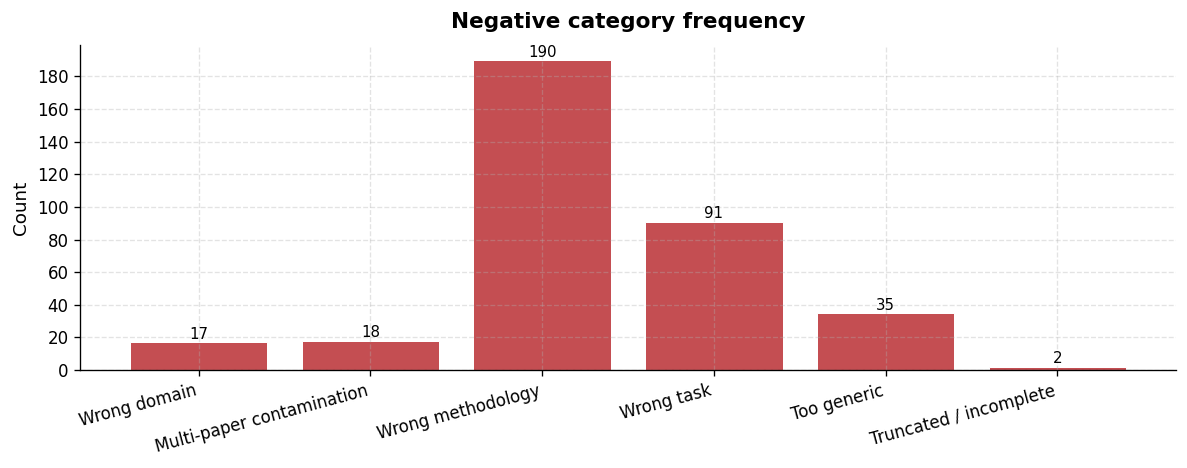

In [12]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


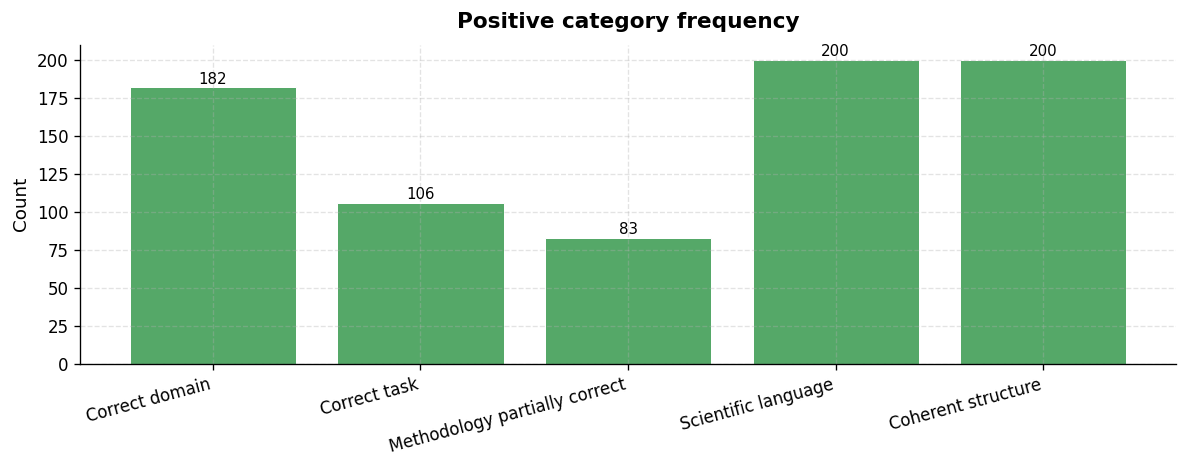

In [13]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()